In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [2]:
(X_train_full, y_train_full), (X_test, y_test) = keras.datasets.boston_housing.load_data()

In [3]:
X_train, X_valid, y_train, y_valid = train_test_split(X_train_full, y_train_full, test_size=0.2, random_state=42)


In [4]:
# a (suite). Prétraitements (Standardisation)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_valid_scaled = scaler.transform(X_valid)
X_test_scaled = scaler.transform(X_test)

In [5]:
# --- 2. Expérimentation avec les algorithmes d'optimisation ---
# c. Construire le réseau de neurones
def build_model():
    model = keras.models.Sequential([
        keras.layers.Dense(64, activation="relu", input_shape=X_train_scaled.shape[1:]),
        keras.layers.Dense(32, activation="relu"),
        keras.layers.Dense(1) # Couche de sortie sans activation (Régression)
    ])
    return model

In [6]:
# Définition des optimiseurs
optimizers = {
    "SGD": keras.optimizers.SGD(learning_rate=0.01),
    "SGD_Momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "RMSProp": keras.optimizers.RMSprop(learning_rate=0.001),
    "Adam": keras.optimizers.Adam(learning_rate=0.001)
}

In [7]:
histories = {}

# Entraînement pour chaque optimiseur
for name, optimizer in optimizers.items():
    print(f"Entraînement en cours avec {name}...")
    model = build_model()
    # Compilation : Loss MSE et Métrique MAE
    model.compile(loss="mse", optimizer=optimizer, metrics=["mae"])
    
    # Entraînement : 50 époques, batch size 32
    history = model.fit(X_train_scaled, y_train, epochs=50, batch_size=32, 
                        validation_data=(X_valid_scaled, y_valid), verbose=0)
    
    histories[name] = history

Entraînement en cours avec SGD...


C:\Users\Dell 5400\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\core\dense.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Entraînement en cours avec SGD_Momentum...
Entraînement en cours avec RMSProp...
Entraînement en cours avec Adam...


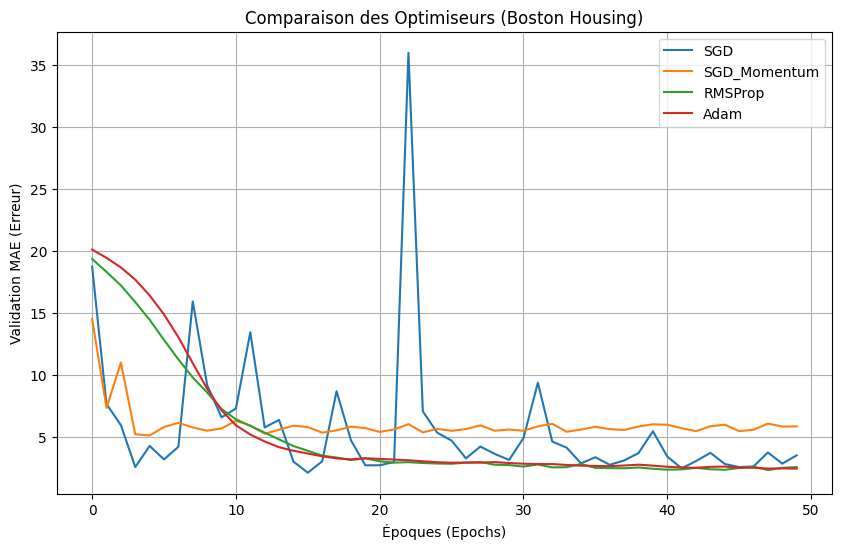

In [11]:

# --- 3. Visualisation des résultats ---
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    # Affichage de la métrique MAE sur les données de validation
    val_mae = history.history['val_mae']
    plt.plot(val_mae, label=name)

plt.xlabel('Époques (Epochs)')
plt.ylabel('Validation MAE (Erreur)')
plt.title('Comparaison des Optimiseurs (Boston Housing)')
plt.legend()
plt.grid(True)
